# Results through experiment 012: 0.5B, 1.5B and 3B

The table uses the predictions saved by the end of experiment 012. The row labelled
“knowledge ceiling (probe)” gives the pretrained model’s accuracy when choosing among the
four answer letters. We use it as a reference score. Generated answers can exceed it,
as the 3B hard-tier result below shows. Overall MC-SFT accuracy was below that score at 0.5B
and close to it at 1.5B and 3B. Across seeds, overall MC-SFT accuracy varied by less
than one percentage point at each size. Warm GRPO varied more at the smaller sizes.
Of the three sizes compared here, only at 3B did Warm GRPO exceed both plain MC-SFT
and the pretrained model's probe accuracy on the hard tier.

In [1]:
import json, os, sys
ROOT = '..' if os.path.basename(os.getcwd()) == 'notebooks' else '.'
sys.path.insert(0, os.path.abspath(ROOT))
import pandas as pd
from analysis.stats import _read_preds
from data.subjects import tier_of

R = os.path.join(ROOT, 'results')

def accs(path):
    # per-tier and overall accuracy straight from a preds file, tiers re-tagged
    # from the subject so old and new files group the same way
    rs = _read_preds(path)
    out = {'overall': sum(r['correct'] for r in rs) / len(rs)}
    for t in ('easy', 'medium', 'hard'):
        xs = [r for r in rs if tier_of(r['subject']) == t]
        out[t] = sum(r['correct'] for r in xs) / len(xs)
    return out

def fmt_of(path):
    # format compliance from the matching eval json, none for probe rows
    if os.path.exists(path):
        return json.load(open(path)).get('format_compliance')
    return None

# every cell of the matrix points at its artifact files, nothing hardcoded
SCALES = {'0.5B': ('006_COLAB_FULL_B05', '005_COLAB_FULL_B05_base_grpo_seed0', '007_p8_COLAB_FULL_B05', '008_wsft_COLAB_FULL_B05', (0, 1, 2)),
          '1.5B': ('009_COLAB_FULL_B15', '012_COLAB_FULL_B15_base_grpo_seed0', '010_p8_COLAB_FULL_B15', '011_wsft_COLAB_FULL_B15', (0, 1)),
          '3B':   ('003_COLAB_FULL_B3', '004_COLAB_FULL_B3_base_grpo_seed0', '007_p8_COLAB_FULL_B3', '008_wsft_COLAB_FULL_B3', (0, 1))}

rows = []
for scale, (core, bg, mc, ws, gseeds) in SCALES.items():
    cells = {
        'base': ([f'{R}/base_evals/{core}/base_preds.jsonl'], [f'{R}/base_evals/{core}/base_eval.json']),
        'knowledge ceiling (probe)': ([f'{R}/base_evals/{core}/base_logprob_preds.jsonl'], []),
        'gsm8k-sft': ([f'{R}/{core}_sft_grpo_seed{s}/sft_preds.jsonl' for s in gseeds],
                      [f'{R}/{core}_sft_grpo_seed{s}/sft_eval.json' for s in gseeds]),
        'base+grpo': ([f'{R}/{bg}/grpo_preds.jsonl'], [f'{R}/{bg}/grpo_eval.json']),
        'sft+grpo': ([f'{R}/{core}_sft_grpo_seed{s}/grpo_preds.jsonl' for s in gseeds],
                     [f'{R}/{core}_sft_grpo_seed{s}/grpo_eval.json' for s in gseeds]),
        'mc-sft': ([f'{R}/{mc}_sft_only_seed{s}/sft_preds.jsonl' for s in (0, 1, 2)],
                   [f'{R}/{mc}_sft_only_seed{s}/sft_eval.json' for s in (0, 1, 2)]),
        'warm-start mc-sft': ([f'{R}/{ws}_sft_only_seed{s}/sft_preds.jsonl' for s in (0, 1, 2)],
                              [f'{R}/{ws}_sft_only_seed{s}/sft_eval.json' for s in (0, 1, 2)]),
    }
    for cond, (paths, evals) in cells.items():
        per = [accs(p) for p in paths]
        ov = [x['overall'] for x in per]
        fmts = [f for f in (fmt_of(e) for e in evals) if f is not None]
        rows.append({'scale': scale, 'condition': cond, 'seeds': len(per),
                     'overall': sum(ov) / len(ov), 'seed range (pt)': (max(ov) - min(ov)) * 100,
                     **{t: sum(x[t] for x in per) / len(per) for t in ('easy', 'medium', 'hard')},
                     'fmt': sum(fmts) / len(fmts) if fmts else float('nan'),
                     '_ov_list': ov})
df = pd.DataFrame(rows)
df.round(3)

,scale,condition,seeds,overall,seed range (pt),easy,medium,hard,fmt,_ov_list
0,0.5B,base,1,0.185,0.000,0.222,0.167,0.131,0.389,[0.18524416135881103]
1,0.5B,knowledge ceiling (probe),1,0.567,0.000,0.687,0.517,0.376,NaN,[0.5668789808917197]
2,0.5B,gsm8k-sft,3,0.224,3.025,0.251,0.211,0.181,0.169,"[0.2085987261146497, 0.23885350318471338, 0.22..."
3,0.5B,base+grpo,1,0.399,0.000,0.488,0.365,0.255,0.018,[0.3991507430997877]
4,0.5B,sft+grpo,3,0.428,19.055,0.534,0.401,0.235,0.927,"[0.46231422505307856, 0.31528662420382164, 0.5..."
5,0.5B,mc-sft,3,0.534,0.796,0.660,0.471,0.351,0.950,"[0.5382165605095541, 0.5334394904458599, 0.530..."
6,0.5B,warm-start mc-sft,3,0.533,0.265,0.660,0.473,0.344,0.992,"[0.5345010615711253, 0.5318471337579618, 0.533..."
7,1.5B,base,1,0.371,0.000,0.431,0.350,0.270,0.649,[0.37101910828025475]
8,1.5B,knowledge ceiling (probe),1,0.692,0.000,0.815,0.695,0.417,NaN,[0.692144373673036]
9,1.5B,gsm8k-sft,2,0.537,2.070,0.633,0.554,0.299,0.898,"[0.5477707006369427, 0.5270700636942676]"


## Master table

In [2]:
# the master table: one row per (scale, condition), best trained condition per
# scale in bold, probe rows in italics as the reference ceiling
show = df.drop(columns='_ov_list').copy()
TRAINED = ['gsm8k-sft', 'base+grpo', 'sft+grpo', 'mc-sft', 'warm-start mc-sft']

def style_master(d):
    sty = d.style.format({'overall': '{:.3f}', 'easy': '{:.3f}', 'medium': '{:.3f}',
                          'hard': '{:.3f}', 'fmt': '{:.3f}', 'seed range (pt)': '{:.1f}'}, na_rep='')
    for scale in d['scale'].unique():
        sub = d[(d['scale'] == scale) & d['condition'].isin(TRAINED)]
        best = sub['overall'].idxmax()
        sty = sty.set_properties(subset=pd.IndexSlice[[best], :], **{'font-weight': 'bold'})
        probe = d[(d['scale'] == scale) & (d['condition'] == 'knowledge ceiling (probe)')].index
        sty = sty.set_properties(subset=pd.IndexSlice[probe, :], **{'font-style': 'italic', 'color': '#666'})
    sty = sty.background_gradient(subset=['overall'], cmap='Greens', vmin=0.15, vmax=0.75)
    sty = sty.set_caption('All results: generative exact-match on the held-out MMLU test set (mean over seeds, validated tiers)')
    return sty.hide(axis='index')

style_master(show)

scale,condition,seeds,overall,seed range (pt),easy,medium,hard,fmt
0.5B,base,1,0.185,0.0,0.222,0.167,0.131,0.389
0.5B,knowledge ceiling (probe),1,0.567,0.0,0.687,0.517,0.376,
0.5B,gsm8k-sft,3,0.224,3.0,0.251,0.211,0.181,0.169
0.5B,base+grpo,1,0.399,0.0,0.488,0.365,0.255,0.018
0.5B,sft+grpo,3,0.428,19.1,0.534,0.401,0.235,0.927
0.5B,mc-sft,3,0.534,0.8,0.660,0.471,0.351,0.950
0.5B,warm-start mc-sft,3,0.533,0.3,0.660,0.473,0.344,0.992
1.5B,base,1,0.371,0.0,0.431,0.350,0.270,0.649
1.5B,knowledge ceiling (probe),1,0.692,0.0,0.815,0.695,0.417,
1.5B,gsm8k-sft,2,0.537,2.1,0.633,0.554,0.299,0.898


## Comparison across three model sizes

The table summarises the runs completed through experiment 012. It shows how seed ranges, format compliance and accuracy differences varied across the three sizes tested here.

In [3]:
# compare seed ranges, format compliance and accuracy differences
# at 0.5B, 1.5B and 3B
def cell(scale, cond, col='overall'):
    return df[(df['scale'] == scale) & (df['condition'] == cond)][col].iloc[0]

def best_grpo_seed(scale):
    return max(df[(df['scale'] == scale) & (df['condition'] == 'sft+grpo')]['_ov_list'].iloc[0])

story = pd.DataFrame({
    s: {
        'grpo seed range (pt)': cell(s, 'sft+grpo', 'seed range (pt)'),
        'supervised seed range (pt)': max(cell(s, 'mc-sft', 'seed range (pt)'), cell(s, 'warm-start mc-sft', 'seed range (pt)')),
        'format without warm start': cell(s, 'base+grpo', 'fmt'),
        'base+grpo deficit vs sft+grpo (pt)': (cell(s, 'base+grpo') - cell(s, 'sft+grpo')) * 100,
        'mc-sft minus BEST grpo seed (pt)': (cell(s, 'mc-sft') - best_grpo_seed(s)) * 100,
        'grpo hard-tier edge over mc-sft (pt)': (cell(s, 'sft+grpo', 'hard') - cell(s, 'mc-sft', 'hard')) * 100,
    } for s in ('0.5B', '1.5B', '3B')})
story.round(2).style.set_caption('Cross-scale gradients: every RL pathology fades with scale, the RL payoff (hard tier) emerges with scale')

,0.5B,1.5B,3B
grpo seed range (pt),19.060000,3.930000,1.060000
supervised seed range (pt),0.800000,0.740000,0.900000
format without warm start,0.020000,0.760000,0.940000
base+grpo deficit vs sft+grpo (pt),-2.870000,-4.560000,-4.460000
mc-sft minus BEST grpo seed (pt),2.810000,1.750000,0.420000
grpo hard-tier edge over mc-sft (pt),-11.620000,-2.610000,3.540000


## Overview figure

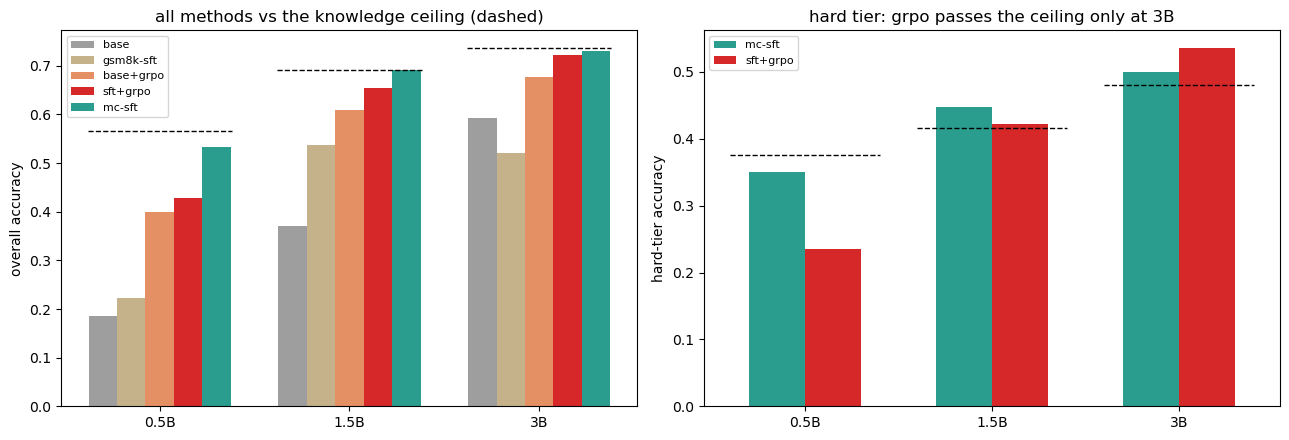

In [4]:
import matplotlib
import matplotlib.pyplot as plt

# two panels: the full picture and the one place grpo earns its cost
FIGDIR = os.path.join(ROOT, 'analysis', 'figures', '010_012_2')
os.makedirs(FIGDIR, exist_ok=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
scales = ['0.5B', '1.5B', '3B']
conds = ['base', 'gsm8k-sft', 'base+grpo', 'sft+grpo', 'mc-sft']
colors = ['#9e9e9e', '#c5b28a', '#e58f65', '#d62828', '#2a9d8f']
w = 0.15
for i, (cond, col) in enumerate(zip(conds, colors)):
    xs = [j + (i - 2) * w for j in range(3)]
    ax1.bar(xs, [cell(s, cond) for s in scales], w, label=cond, color=col)
for j, s in enumerate(scales):
    ax1.hlines(cell(s, 'knowledge ceiling (probe)'), j - 0.38, j + 0.38, ls='--', color='k', lw=1)
ax1.set_xticks(range(3)); ax1.set_xticklabels(scales)
ax1.set_ylabel('overall accuracy'); ax1.set_title('all methods vs the knowledge ceiling (dashed)')
ax1.legend(fontsize=8, loc='upper left')

for i, (cond, col) in enumerate([('mc-sft', '#2a9d8f'), ('sft+grpo', '#d62828')]):
    xs = [j + (i - 0.5) * 0.3 for j in range(3)]
    ax2.bar(xs, [cell(s, cond, 'hard') for s in scales], 0.3, label=cond, color=col)
for j, s in enumerate(scales):
    ax2.hlines(cell(s, 'knowledge ceiling (probe)', 'hard'), j - 0.4, j + 0.4, ls='--', color='k', lw=1)
ax2.set_xticks(range(3)); ax2.set_xticklabels(scales)
ax2.set_ylabel('hard-tier accuracy'); ax2.set_title('hard tier: grpo passes the ceiling only at 3B')
ax2.legend(fontsize=8, loc='upper left')
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_matrix_overview.png'), dpi=200, bbox_inches='tight')
plt.show()

## Save everything

In [5]:
# save the tables next to the figure
show.to_csv(os.path.join(FIGDIR, 'matrix_summary.csv'), index=False)
story.round(3).to_csv(os.path.join(FIGDIR, 'story_gradients.csv'))
with open(os.path.join(FIGDIR, 'matrix_summary.html'), 'w') as f:
    f.write(style_master(show).to_html())
print('saved to', FIGDIR)

saved to ../analysis/figures/010_012_2


## Training reward curves: was there anything left to learn at step 500?

These curves show the accuracy reward on the 245 training questions through update 500. Later experiments measured accuracy on held-out questions after [restarting training at 0.5B](020_1_analysis_plots.ipynb) and [comparing updates 500 and 1,000 within the same training runs at 7B](022_1_analysis_plots.ipynb).

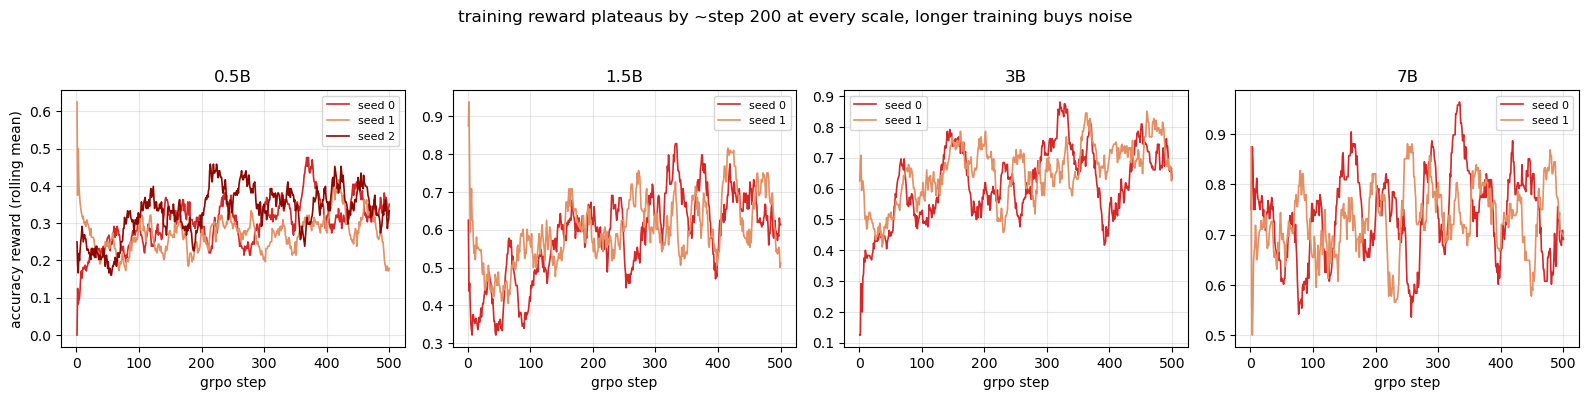

In [6]:
import json, os
import matplotlib.pyplot as plt

ROOT = '..' if os.path.basename(os.getcwd()) == 'notebooks' else '.'
R = os.path.join(ROOT, 'results')
FIGDIR = os.path.join(ROOT, 'analysis', 'figures', '010_012_2')
os.makedirs(FIGDIR, exist_ok=True)

def reward_curve(path, window=20):
    # rolling mean over the per step accuracy reward so the trend is readable
    tl = json.load(open(path))
    xs, ys = [], []
    for e in tl:
        if 'rewards/accuracy_reward/mean' in e and 'step' in e:
            xs.append(e['step']); ys.append(e['rewards/accuracy_reward/mean'])
    smooth = [sum(ys[max(0, i - window):i + 1]) / len(ys[max(0, i - window):i + 1]) for i in range(len(ys))]
    return xs, smooth

PANELS = [('0.5B', [(f'006_COLAB_FULL_B05_sft_grpo_seed{s}', f'seed {s}') for s in (0, 1, 2)]),
          ('1.5B', [(f'009_COLAB_FULL_B15_sft_grpo_seed{s}', f'seed {s}') for s in (0, 1)]),
          ('3B',   [(f'003_COLAB_FULL_B3_sft_grpo_seed{s}', f'seed {s}') for s in (0, 1)]),
          ('7B',   [(f'013_COLAB_FULL_B7_sft_grpo_seed{s}', f'seed {s}') for s in (0, 1)])]
COLS = ['#d62828', '#e58f65', '#8d0801']

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharex=True)
for ax, (scale, runs) in zip(axes, PANELS):
    for (tag, lab), col in zip(runs, COLS):
        xs, ys = reward_curve(os.path.join(R, tag, 'grpo_trainlog.json'))
        ax.plot(xs, ys, color=col, label=lab, lw=1.2)
    ax.set_title(f'{scale}')
    ax.set_xlabel('grpo step')
    ax.grid(alpha=.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel('accuracy reward (rolling mean)')
fig.suptitle('training reward plateaus by ~step 200 at every scale, longer training buys noise', y=1.04)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_reward_plateau.png'), dpi=200, bbox_inches='tight')
plt.show()